# Target & modelling-cohort audit — BPI Challenge 2015, Municipality 1

**Research question:** *Can information available early in an administrative case predict whether it will become a long-running case?*

This notebook makes and documents the methodological decisions needed before feature engineering:
which cases form the modelling cohort, which duration defines "long-running", the exact threshold,
the prediction point, and the evaluation strategy. It builds on `02_eda.ipynb` and does not change its conclusions.

**Scope (decision step only):**

- The raw XES is read only.
- No predictive features are engineered, no training dataset is saved, no train/test split is made, and no model is trained or tuned.
- Labels are computed **in memory only** to report class counts. Nothing is written to `data/processed/`.
- No case is silently excluded: every cohort rule is stated, counted and justified.

**Terminology.** There is no evidence in the data that the target reflects a legal deadline breach, statutory delay, formal lateness or poor performance.
The notebook therefore speaks only of a **long-running case** and of the **risk of becoming long-running**.

# 1. Imports and constants

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pm4py

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

SECONDS_PER_DAY = 24 * 60 * 60
LOCAL_TIMEZONE = "Europe/Amsterdam"
EXPECTED_EVENT_ROWS = 52_217
EXPECTED_CASES = 1_199

# Percentiles requested for the threshold audit
AUDIT_PERCENTILES = [0.50, 0.75, 0.80, 0.90, 0.95]
# Long-running = above the upper quartile (see Section 6 for why P75 and not P80/P90)
THRESHOLD_PERCENTILE = 0.75
# Percentile convention: pandas default = linear interpolation between order statistics (Hyndman & Fan type 7, same as numpy "linear")
QUANTILE_METHOD = "linear"

# Disagreement bands between duration definitions (one week, about one month, about one quarter)
DISAGREEMENT_BANDS_DAYS = [7, 30, 90]
# Candidate data-quality rule for Target C (justified in Section 5): endDate more than this many days after the last logged event
MAX_UNSUPPORTED_END_GAP_DAYS = 60
# Prediction-point options (Section 9)
PREFIX_EVENT_OPTIONS = [3, 5]
ELAPSED_DAY_OPTIONS = [7, 14, 30]
RECOMMENDED_PREDICTION_DAY = 14
# Minimum follow-up discussed for evaluation (Section 10)
MIN_FOLLOW_UP_DAYS = 365
TOP_N_EXTREME = 10



  Welcome to PM4Py — Community Version
  Open-Source License (AGPL v3)

  📚 Docs & Examples:
     https://processintelligence.solutions/pm4py

  ⚖️  License: AGPL v3 — Commercial use requires open-sourcing your application.
     Business use without open-sourcing? A commercial license is available:
     https://processintelligence.solutions/pm4py#licensing




# 2. Paths and loading

Same robust project-root search as the earlier notebooks; counts must match the validated intake.

In [2]:
candidates = [Path.cwd(), *Path.cwd().parents]
project_root = next(
    (folder for folder in candidates
     if (folder / "notebooks" / "01_data_loading.ipynb").is_file()
     and (folder / "src").is_dir()),
    None,
)
if project_root is None:
    raise FileNotFoundError("Start Jupyter from inside the capstone project.")
xes_path = project_root / "data" / "raw" / "BPIC15_1.xes"
if not xes_path.is_file():
    raise FileNotFoundError("Place BPIC15_1.xes in data/raw/ before running this notebook.")
figures_dir = project_root / "outputs" / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)

df = pm4py.convert_to_dataframe(pm4py.read_xes(str(xes_path), return_legacy_log_object=True))
CASE, ACTIVITY, TIMESTAMP = "case:concept:name", "concept:name", "time:timestamp"
n_events, n_cases = len(df), df[CASE].nunique()
print(f"Event rows: {n_events:,}   Cases: {n_cases:,}")
if (n_events, n_cases) != (EXPECTED_EVENT_ROWS, EXPECTED_CASES):
    raise RuntimeError("STOP: counts differ from the validated intake counts.")
extract_end = df[TIMESTAMP].max()
print("Last timestamp in the extract:", extract_end)

C:\SPAR_CAPSTONE\.venv\Lib\site-packages\pm4py\utils.py:1027: UserWarning: Install the optional requirement `r4pm` to import/export files faster. `rustxes` remains supported as a fallback.
  warnings.warn(


Event rows: 52,217   Cases: 1,199
Last timestamp in the extract: 2015-07-31 22:00:00+00:00


# 3. Case-level durations (in memory)

Two duration definitions, as in `02_eda.ipynb`:

- **Administrative duration** = `case:startDate` → `case:endDate` (only where an end date exists).
- **Event-log duration** = first logged event → last logged event.

`end_gap_days` = `case:endDate` − last event. Positive means the recorded end date lies *after* the last logged activity.

In [3]:
grouped = df.groupby(CASE, sort=False)
case_attributes = ["case:startDate", "case:endDate", "case:requestComplete", "case:caseStatus", "case:last_phase", "case:termName"]
cases = grouped[case_attributes].first()
cases["first_event_time"] = grouped[TIMESTAMP].min()
cases["last_event_time"] = grouped[TIMESTAMP].max()
cases["event_count"] = grouped.size()


def days_between(start, end):
    return (end - start).dt.total_seconds() / SECONDS_PER_DAY


cases["administrative_days"] = days_between(cases["case:startDate"], cases["case:endDate"])
cases["event_log_days"] = days_between(cases["first_event_time"], cases["last_event_time"])
cases["start_gap_days"] = days_between(cases["case:startDate"], cases["first_event_time"])
cases["end_gap_days"] = days_between(cases["last_event_time"], cases["case:endDate"])
cases["start_year"] = cases["case:startDate"].dt.tz_convert(LOCAL_TIMEZONE).dt.year

has_end_date = cases["case:endDate"].notna()
request_complete = cases["case:requestComplete"].str.upper().eq("TRUE")
print("Cases:", len(cases))

Cases: 1199


# 4. The four completion groups

The two completion indicators split the 1,199 cases into four groups. The audit starts from the **strict 774-case group**
(end date present AND `requestComplete = TRUE`) and then tests whether that restriction is justified.

In [4]:
completion_group = pd.Series(
    np.select(
        [has_end_date & request_complete, has_end_date & ~request_complete, ~has_end_date & request_complete],
        ["1: endDate + requestComplete TRUE", "2: endDate + requestComplete FALSE", "3: no endDate + requestComplete TRUE"],
        "4: no endDate + requestComplete FALSE",
    ),
    index=cases.index, name="completion_group",
)
group_profile = cases.groupby(completion_group).agg(
    cases=("event_log_days", "size"),
    median_event_log_days=("event_log_days", "median"),
    p75_event_log_days=("event_log_days", lambda s: s.quantile(0.75)),
    median_administrative_days=("administrative_days", "median"),
    median_events=("event_count", "median"),
).round(1)
display(group_profile)

print("Most common last_phase per group:")
for name, members in cases.groupby(completion_group):
    print(f"\n{name}")
    print(members["case:last_phase"].value_counts().head(4).to_string())

,cases,median_event_log_days,p75_event_log_days,median_administrative_days,median_events
completion_group,,,,,
1: endDate + requestComplete TRUE,774,58.0,93.4,55.0,44.0
2: endDate + requestComplete FALSE,182,93.3,167.5,102.5,57.0
3: no endDate + requestComplete TRUE,174,41.0,63.8,NaN,20.5
4: no endDate + requestComplete FALSE,69,86.0,153.0,NaN,37.0


Most common last_phase per group:

1: endDate + requestComplete TRUE
case:last_phase
Vergunning verleend      308
Beschikking verzonden    257
Zaak afgehandeld          83
Procedure afgebroken      41

2: endDate + requestComplete FALSE
case:last_phase
Beschikking verzonden         79
Zaak afgehandeld              23
Vergunning verleend           22
Buiten behandeling gelaten    17

3: no endDate + requestComplete TRUE
case:last_phase
Aanvraag ontvangen       50
Beschikking verzonden    42
Procedure afgebroken     32
Vergunning verleend      13

4: no endDate + requestComplete FALSE
case:last_phase
Beschikking verzonden             22
Buiten behandeling gelaten        10
Aanvullende gegevens gevraagd      8
Aanvullende gegevens ontvangen     6


# 5. Audit of the strict 774-case cohort

### 5.1 Duration distributions and thresholds

**Convention:** percentiles use pandas' default linear interpolation (Hyndman & Fan type 7).
"Above P75" is reported with both a strict (`>`) and an inclusive (`>=`) comparison.

In [5]:
strict_cohort = cases[has_end_date & request_complete]
print("Strict cohort cases:", len(strict_cohort))


def percentile_table(frame, columns):
    table = frame[columns].quantile(AUDIT_PERCENTILES, interpolation=QUANTILE_METHOD)
    table.index = [f"P{round(p * 100)}" for p in AUDIT_PERCENTILES]
    table.loc["maximum"] = frame[columns].max()
    table.loc["count"] = frame[columns].count()
    return table.round(2)


duration_columns = ["administrative_days", "event_log_days"]
display(percentile_table(strict_cohort, duration_columns))


def class_counts(durations):
    threshold = durations.quantile(THRESHOLD_PERCENTILE, interpolation=QUANTILE_METHOD)
    return {
        "threshold_days (P75)": round(threshold, 2),
        "positives (> P75)": int((durations > threshold).sum()),
        "positives (>= P75)": int((durations >= threshold).sum()),
        "cases exactly at P75": int((durations == threshold).sum()),
        "negatives (<= P75)": int((durations <= threshold).sum()),
        "positive % (> P75)": round((durations > threshold).mean() * 100, 1),
    }


display(pd.DataFrame({column: class_counts(strict_cohort[column]) for column in duration_columns}))

Strict cohort cases: 774


,administrative_days,event_log_days
P50,55.04,58.00
P75,93.03,93.37
P80,96.98,102.99
P90,176.07,161.59
P95,330.40,259.09
maximum,1540.49,1486.00
count,774.00,774.00


,administrative_days,event_log_days
threshold_days (P75),93.03,93.37
positives (> P75),194.00,194.00
positives (>= P75),194.00,194.00
cases exactly at P75,0.00,0.00
negatives (<= P75),580.00,580.00
positive % (> P75),25.10,25.10


No duration equals the P75 value exactly, so `>` and `>=` give the same counts here. The recommendation still fixes the
convention explicitly as **strictly greater than** (`>`), so the rule stays unambiguous if the data change.
The ~25% positive share follows from the percentile choice; it is not the reason for it (see Section 6).

### 5.2 Completion-cohort robustness

The strict cohort is compared with (A) all cases with an end date and (B) all `requestComplete = TRUE` cases.
For (B), cases without an end date have only a *partial* event-log duration (they were cut off by the end of the extract).

In [6]:
cohort_masks = {
    "strict: endDate + requestComplete TRUE": has_end_date & request_complete,
    "A: endDate present": has_end_date,
    "B: requestComplete TRUE (incl. no endDate)": request_complete,
}
robustness = {}
for name, mask in cohort_masks.items():
    durations = cases.loc[mask, "event_log_days"]
    row = {"cases": int(mask.sum()), "without endDate": int((mask & ~has_end_date).sum())}
    row.update({f"P{round(p * 100)}": round(durations.quantile(p), 1) for p in AUDIT_PERCENTILES})
    row.update(class_counts(durations))
    robustness[name] = row
display(pd.DataFrame(robustness).T)

,cases,without endDate,P50,P75,P80,P90,P95,threshold_days (P75),positives (> P75),positives (>= P75),cases exactly at P75,negatives (<= P75),positive % (> P75)
strict: endDate + requestComplete TRUE,774.0,0.0,58.0,93.4,103.0,161.6,259.1,93.37,194.0,194.0,0.0,580.0,25.1
A: endDate present,956.0,0.0,63.0,102.5,112.4,203.8,307.4,102.53,239.0,239.0,0.0,717.0,25.0
B: requestComplete TRUE (incl. no endDate),948.0,174.0,55.0,88.0,97.6,155.2,254.0,88.01,237.0,237.0,0.0,711.0,25.0


In [7]:
excluded_by_request_flag = cases[has_end_date & ~request_complete]
strict_threshold_event_log = strict_cohort["event_log_days"].quantile(THRESHOLD_PERCENTILE)
print(f"Cases with endDate but requestComplete FALSE: {len(excluded_by_request_flag)}")
print(f"  share above the strict-cohort P75 ({strict_threshold_event_log:.1f} days): "
      f"{(excluded_by_request_flag['event_log_days'] > strict_threshold_event_log).mean():.1%}  "
      f"(strict cohort: {(strict_cohort['event_log_days'] > strict_threshold_event_log).mean():.1%})")

print("\nCompletion groups by start year:")
display(pd.crosstab(cases["start_year"], completion_group, margins=True))

Cases with endDate but requestComplete FALSE: 182
  share above the strict-cohort P75 (93.4 days): 50.0%  (strict cohort: 25.1%)

Completion groups by start year:


completion_group,1: endDate + requestComplete TRUE,2: endDate + requestComplete FALSE,3: no endDate + requestComplete TRUE,4: no endDate + requestComplete FALSE,All
start_year,,,,,
2010,55,0,23,0,78
2011,268,30,48,7,353
2012,214,51,25,12,302
2013,129,56,8,9,202
2014,102,44,49,40,235
2015,6,1,21,1,29
All,774,182,174,69,1199


**What the comparison shows.**

- The cases excluded by `requestComplete = FALSE` (group 2) **look finished**: their last phases are mostly decisions sent / permit granted / case handled, and they have an end date.
- They are **markedly longer** than the strict cohort: about half of them would be "long-running" under the strict-cohort threshold, roughly twice the strict-cohort rate.
- The name `requestComplete` suggests *completeness of the application* rather than completion of the case. Its meaning is undocumented, but the data do not support using it as a completion indicator. Requiring it removes a real source of long-running cases, so the strict cohort is **biased towards shorter cases**. The group-2 share also varies over time (more in 2012–2014), which would interact with a chronological evaluation.
- Using all end-date cases (A) shifts P75 up by about 9 days and adds 182 cases. The broader `requestComplete = TRUE` view (B) mixes in cases without an end date, whose durations are truncated.

### Why cases without a reliable final duration cannot be negatives

For a case without a recorded end, the observed duration is only a **lower bound** of its final duration (right-censoring).
A case that has been observed for 40 days may still run for 400. Labelling it "not long-running" would systematically
mislabel exactly the cases that are still open, which are the long ones. Section 7 quantifies this. These cases are therefore
**kept out of the labelled cohort**. They are not deleted from the data, and they are listed as a limitation.

# 6. Duration-definition audit

Agreement between the administrative duration and the event-log duration in the strict cohort (as requested) and in the all-end-date cohort.

In [8]:
def agreement_stats(frame):
    difference = frame["event_log_days"] - frame["administrative_days"]
    absolute = difference.abs()
    stats = {
        "cases": len(frame),
        "Pearson": round(frame["event_log_days"].corr(frame["administrative_days"]), 3),
        "Spearman": round(frame["event_log_days"].corr(frame["administrative_days"], method="spearman"), 3),
        "median |difference| (days)": round(absolute.median(), 1),
        "P75 |difference| (days)": round(absolute.quantile(0.75), 1),
        "P90 |difference| (days)": round(absolute.quantile(0.90), 1),
    }
    for band in DISAGREEMENT_BANDS_DAYS:
        stats[f"|difference| > {band} days"] = int((absolute > band).sum())
    stats["administrative longer by > 30 days"] = int((difference < -30).sum())
    stats["event log longer by > 30 days"] = int((difference > 30).sum())
    return stats


end_date_cohort = cases[has_end_date]
display(pd.DataFrame({"strict cohort": agreement_stats(strict_cohort), "endDate cohort": agreement_stats(end_date_cohort)}))

,strict cohort,endDate cohort
cases,774.000,956.000
Pearson,0.474,0.528
Spearman,0.766,0.798
median |difference| (days),8.000,8.000
P75 |difference| (days),13.000,17.000
P90 |difference| (days),43.000,43.000
|difference| > 7 days,453.000,555.000
|difference| > 30 days,143.000,194.000
|difference| > 90 days,38.000,48.000
administrative longer by > 30 days,97.000,132.000


### 6.1 Where do the disagreements come from?

A disagreement can come from the **start** (`startDate` vs first event) or the **end** (`endDate` vs last event).

In [9]:
for name, frame in [("strict cohort", strict_cohort), ("endDate cohort", end_date_cohort)]:
    print(f"{name}: start gap |>1 day|: {(frame['start_gap_days'].abs() > 1).sum()} cases; "
          f"end gap |>1 day|: {(frame['end_gap_days'].abs() > 1).sum()} cases")

gap_bins = [-np.inf, -30, -1, 1, 30, 41, 44, MAX_UNSUPPORTED_END_GAP_DAYS, 365, np.inf]
gap_labels = ["last event > 30 d after endDate", "last event 1–30 d after endDate", "same day (±1 d)",
              "endDate 1–30 d after last event", "endDate 30–41 d after", "endDate 41–44 d after",
              f"endDate 44–{MAX_UNSUPPORTED_END_GAP_DAYS} d after", f"endDate {MAX_UNSUPPORTED_END_GAP_DAYS}–365 d after",
              "endDate > 365 d after last event"]
end_gap_band = pd.cut(end_date_cohort["end_gap_days"], bins=gap_bins, labels=gap_labels)
display(end_gap_band.value_counts(sort=False).rename("cases (endDate cohort)").to_frame())

print("termName of cases whose endDate is 41–44 days after the last event:")
print(end_date_cohort.loc[end_gap_band == "endDate 41–44 d after", "case:termName"].value_counts(dropna=False).to_string())

strict cohort: start gap |>1 day|: 13 cases; end gap |>1 day|: 572 cases
endDate cohort: start gap |>1 day|: 14 cases; end gap |>1 day|: 696 cases


,cases (endDate cohort)
end_gap_days,
last event > 30 d after endDate,55
last event 1–30 d after endDate,503
same day (±1 d),244
endDate 1–30 d after last event,22
endDate 30–41 d after,22
endDate 41–44 d after,73
endDate 44–60 d after,4
endDate 60–365 d after,11
endDate > 365 d after last event,22


termName of cases whose endDate is 41–44 days after the last event:
case:termName
Termijn bezwaar en beroep 1               71
Termijn tot bezwaar buiten behandeling     1
Termijn tot besluit                        1


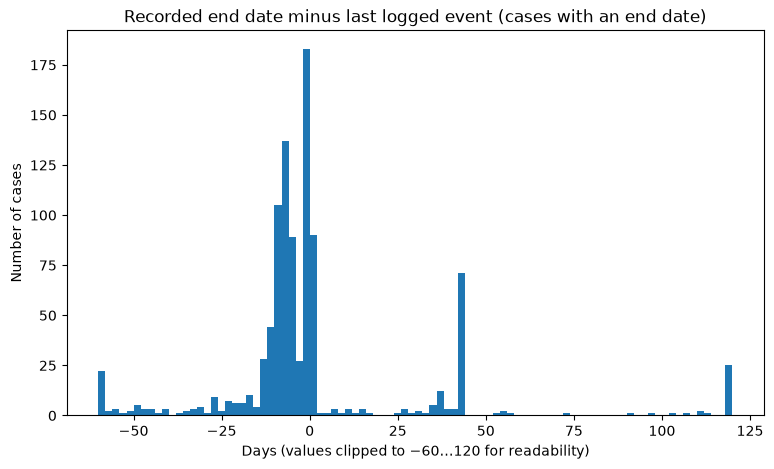

In [10]:
plt.figure(figsize=(9, 5))
clipped_gap = end_date_cohort["end_gap_days"].clip(-60, 120)
plt.hist(clipped_gap, bins=np.arange(-60, 122, 2))
plt.title("Recorded end date minus last logged event (cases with an end date)")
plt.xlabel("Days (values clipped to −60…120 for readability)")
plt.ylabel("Number of cases")
plt.show()

In [11]:
difference = end_date_cohort["event_log_days"] - end_date_cohort["administrative_days"]
print(f"Most extreme disagreements (top {TOP_N_EXTREME} by |difference|, endDate cohort):")
display(
    end_date_cohort.assign(difference_days=difference)
    .reindex(difference.abs().sort_values(ascending=False).index)
    .head(TOP_N_EXTREME)[["case:startDate", "last_event_time", "case:endDate", "event_log_days", "administrative_days",
                           "difference_days", "event_count", "case:requestComplete", "case:last_phase"]]
    .round({"event_log_days": 1, "administrative_days": 1, "difference_days": 1})
)

case_end_per_event = df[CASE].map(end_date_cohort["case:endDate"])  # NaT for cases without endDate
after_end = df[df[TIMESTAMP] > case_end_per_event + pd.Timedelta(days=1)]
print(f"Events logged more than 1 day after endDate: {len(after_end):,} in {after_end[CASE].nunique()} cases. Most common:")
print(after_end["activityNameEN"].value_counts().head(8).to_string())

Most extreme disagreements (top 10 by |difference|, endDate cohort):


,case:startDate,last_event_time,case:endDate,event_log_days,administrative_days,difference_days,event_count,case:requestComplete,case:last_phase
case:concept:name,,,,,,,,,
2876753,2010-11-22 23:00:00+00:00,2010-11-26 10:17:52+00:00,2015-01-06 15:13:24+00:00,3.5,1505.7,-1502.2,6,TRUE,Procedure afgebroken
2874224,2010-11-17 23:00:00+00:00,2011-01-12 23:00:00+00:00,2015-01-06 16:16:03+00:00,56.0,1510.7,-1454.7,39,TRUE,Aanvraag ontvangen
3020566,2011-01-11 23:00:00+00:00,2011-01-20 13:36:38+00:00,2015-01-06 15:18:18+00:00,8.6,1455.7,-1447.1,6,TRUE,Aanvraag ontvangen
2866083,2010-11-10 23:00:00+00:00,2011-01-24 23:00:00+00:00,2015-01-06 15:29:06+00:00,75.0,1517.7,-1442.7,23,TRUE,Aanvraag ontvankelijk
3019503,2011-01-05 23:00:00+00:00,2011-05-04 14:25:32+00:00,2015-01-06 15:29:40+00:00,118.6,1461.7,-1343.0,27,TRUE,Aanvraag ontvangen
2760925,2010-10-04 22:00:00+00:00,2010-10-07 12:57:14+00:00,2014-06-10 12:13:27+00:00,2.6,1344.6,-1342.0,2,TRUE,Buiten behandeling gelaten
2887729,2010-11-22 23:00:00+00:00,2011-12-27 23:00:00+00:00,2015-02-10 10:51:41+00:00,400.0,1540.5,-1140.5,55,TRUE,Vergunning verleend
2992191,2010-12-30 23:00:00+00:00,2011-04-21 13:27:53+00:00,2014-05-22 08:56:55+00:00,111.6,1238.4,-1126.8,40,TRUE,Procedure afgebroken
4088369,2011-11-07 23:00:00+00:00,2011-12-27 23:00:00+00:00,2014-12-23 10:50:00+00:00,50.0,1141.5,-1091.5,35,TRUE,Vergunning verleend


Events logged more than 1 day after endDate: 2,055 in 542 cases. Most common:
activityNameEN
enter date publication decision environmental permit    297
read publication date field                             130
close case                                              100
objection lodged against decision                        94
enter senddate decision environmental permit             83
date decision for inspection                             82
phase decision irrevocable                               80
phase case handled                                       70


**Anomaly assessment.**

- **Starts agree.** Almost every first event falls on the `startDate` day. All disagreement is at the **end**.
- **Small systematic offsets (both directions, days to weeks).** In most cases the last event comes a few days to two weeks *after* `endDate`; the activities logged then are publication, close-case and archiving steps. In a distinct cluster, `endDate` is set **41–44 days after** the last event, almost exclusively in cases with termName *Termijn bezwaar en beroep 1* (literally "objection and appeal term"). This looks like an end date set at the end of a fixed waiting period. The administrative duration therefore includes a **fixed waiting time** for part of the cases, independent of how the case was processed. No legal meaning is assumed; the pattern is just visible in the data.
- **Large anomalies are concentrated in the administrative definition.** A small group of cases has an `endDate` months to years after the last logged activity. Several of these stopped at an early phase (e.g. *Aanvraag ontvangen*, "application received") and have very few events, i.e. activity stopped early and the case was closed administratively much later. Their administrative duration (often > 3 years) measures **when the file was closed**, not how long the case was worked on.
- **The opposite direction exists too.** In some cases events continue long after `endDate` (e.g. *objection lodged against decision*, *phase decision irrevocable*). These are genuine logged process steps.
- No date is repaired or altered.

In [12]:
threshold_admin = end_date_cohort["administrative_days"].quantile(THRESHOLD_PERCENTILE)
threshold_log = end_date_cohort["event_log_days"].quantile(THRESHOLD_PERCENTILE)
label_admin = end_date_cohort["administrative_days"] > threshold_admin
label_log = end_date_cohort["event_log_days"] > threshold_log
print("Label agreement (endDate cohort, each definition with its own P75):")
display(pd.crosstab(label_log.rename("event-log long-running"), label_admin.rename("administrative long-running"), margins=True))

print("Positive rate (%) by start year under each definition:")
display(pd.DataFrame({
    "cases": end_date_cohort.groupby("start_year").size(),
    "administrative": label_admin.groupby(end_date_cohort["start_year"]).mean().mul(100).round(1),
    "event log": label_log.groupby(end_date_cohort["start_year"]).mean().mul(100).round(1),
}))

Label agreement (endDate cohort, each definition with its own P75):


administrative long-running,False,True,All
event-log long-running,,,
False,660,57,717
True,57,182,239
All,717,239,956


Positive rate (%) by start year under each definition:


,cases,administrative,event log
start_year,,,
2010,55,38.2,34.5
2011,298,19.1,25.8
2012,265,23.4,24.2
2013,185,29.7,30.3
2014,146,30.1,15.8
2015,7,0.0,0.0


The two labels agree for most cases but differ for a meaningful minority (each definition labels positives the other does not).
For **2014 starts** the two definitions move in opposite directions. The event-log positive rate drops, which is consistent with
right-censoring: long 2014 cases had often not closed yet. The administrative rate stays high, which is consistent with end dates
being set well after activity stopped (late administrative closure) and inflating administrative durations. Either way, the
administrative label behaves differently exactly in the most recent cohort, which is the one a chronological evaluation tests on.

# 7. Right-censoring: open cases and the "already long" problem

In [13]:
open_cases = cases[~has_end_date]
print(f"Cases without endDate: {len(open_cases)}")
print(f"  already observed longer than the endDate-cohort event-log P75 ({threshold_log:.1f} days): "
      f"{(open_cases['event_log_days'] > threshold_log).sum()}")
idle_days = days_between(open_cases["last_event_time"], pd.Series(extract_end, index=open_cases.index))
print("  days from last logged event to end of extract:")
print(idle_days.describe().round(0).to_string())

Cases without endDate: 243
  already observed longer than the endDate-cohort event-log P75 (102.5 days): 39
  days from last logged event to end of extract:
count     243.0
mean      793.0
std       574.0
min         0.0
25%       226.0
50%       663.0
75%      1382.0
max      1746.0


A sixth of the cases without an end date have **already** been observed for longer than the threshold. Labelling them negative
would be plainly wrong, and for the rest the final duration is unknown. Many also show no logged activity for a long time before the extract ends, so they are neither clearly finished nor clearly
active. Their true duration cannot be determined from the log. They are excluded from the **labelled** cohort for that reason,
and this selection is a stated limitation: the labelled cohort contains only cases whose closure was recorded.

# 8. Target candidates

### Target C — is there a defensible data-quality rule?

The only candidate rule that can be stated without looking at model results is based on the end-gap distribution in Section 6.1:
*exclude cases whose `endDate` lies more than `MAX_UNSUPPORTED_END_GAP_DAYS` (60) days after the last logged event*, i.e. the
end date is not supported by any logged activity. The value 60 sits in the empty region after the 41–44-day cluster, so the
fixed-term cases are kept.

It is computed below for comparison.

In [14]:
supported_end = end_date_cohort["end_gap_days"] <= MAX_UNSUPPORTED_END_GAP_DAYS
target_c_cohort = end_date_cohort[supported_end]
print(f"Target C rule removes {(~supported_end).sum()} of {len(end_date_cohort)} endDate cases")


def candidate_summary(name, durations, duration_label, cohort_label):
    threshold = durations.quantile(THRESHOLD_PERCENTILE, interpolation=QUANTILE_METHOD)
    positives = int((durations > threshold).sum())
    return {
        "candidate": name, "duration": duration_label, "cohort": cohort_label, "cases": len(durations),
        "P75 threshold (days)": round(threshold, 2), "positives": positives,
        "negatives": len(durations) - positives, "positive %": round(positives / len(durations) * 100, 1),
    }


candidates_table = pd.DataFrame([
    candidate_summary("A", end_date_cohort["administrative_days"], "startDate → endDate", "endDate present"),
    candidate_summary("A (strict)", strict_cohort["administrative_days"], "startDate → endDate", "endDate + requestComplete"),
    candidate_summary("B", end_date_cohort["event_log_days"], "first → last event", "endDate present"),
    candidate_summary("B (strict)", strict_cohort["event_log_days"], "first → last event", "endDate + requestComplete"),
    candidate_summary("C", target_c_cohort["administrative_days"], "startDate → endDate", f"endDate ≤ last event + {MAX_UNSUPPORTED_END_GAP_DAYS} d"),
]).set_index("candidate")
display(candidates_table)

print("Sensitivity of Target B (endDate cohort) to the percentile choice:")
for percentile in AUDIT_PERCENTILES[1:]:
    cut = end_date_cohort["event_log_days"].quantile(percentile)
    print(f"  P{round(percentile * 100)}: threshold {cut:6.1f} days -> {int((end_date_cohort['event_log_days'] > cut).sum())} positives")

Target C rule removes 33 of 956 endDate cases


,duration,cohort,cases,P75 threshold (days),positives,negatives,positive %
candidate,,,,,,,
A,startDate → endDate,endDate present,956,98.17,239,717,25.0
A (strict),startDate → endDate,endDate + requestComplete,774,93.03,194,580,25.1
B,first → last event,endDate present,956,102.53,239,717,25.0
B (strict),first → last event,endDate + requestComplete,774,93.37,194,580,25.1
C,startDate → endDate,endDate ≤ last event + 60 d,923,96.00,227,696,24.6


Sensitivity of Target B (endDate cohort) to the percentile choice:
  P75: threshold  102.5 days -> 239 positives
  P80: threshold  112.4 days -> 191 positives
  P90: threshold  203.8 days -> 96 positives
  P95: threshold  307.4 days -> 48 positives


| Criterion | **Target A** — administrative duration > P75 | **Target B** — event-log duration > P75 | **Target C** — administrative duration > P75 after gap rule |
|---|---|---|---|
| Semantic meaning | Time until the file was formally closed, including fixed waiting periods and late closures. | Time over which the case had **logged activity**, from first to last recorded step. | Like A, without the cases closed long after activity stopped. |
| Data quality | Large anomalies are concentrated here (end dates years after activity). The 41–44-day fixed-term offset is part of the value. | Derived from event timestamps only. Date resolution is a day; post-decision steps (objection, publication) are included as logged. | Removes the gross anomalies, keeps the fixed-term offset. |
| Sample size | Full end-date cohort. | Full end-date cohort. | A few dozen fewer cases. |
| Class balance | ≈25% by construction. | ≈25% by construction. | ≈25% by construction. |
| Reproducibility | Simple rule. | Simple rule. | Needs an extra tunable cut-off (60 days); another analyst could reasonably pick 90 or 365. |
| Presentation clarity | Easy to say, hard to defend once the anomalies are shown. | Easy to say: "from first to last recorded step". | Needs a caveat slide. |
| Risk of labelling artefacts | High: time-concentrated artefact (2014 jump), late closures labelled long-running. | Lower. Main risk: a stray late event lengthens a case. | Medium: residual dependence on how closure dates were set. |
| Early-prediction compatibility | Clock starts at `startDate` ≈ first event; fine. | Clock starts at first event, the same clock used at prediction time. | As A. |

**Verdict on Target C.** A rule can be written down, but it is an extra judgement threshold. It removes cases selectively from the
upper tail of the very variable that defines the label, and it still leaves the fixed waiting-time offset in the duration. Target B
avoids the same anomalies **without excluding any case**. C is therefore kept only as a sensitivity check, not as the target.

**Why P75.** The upper quartile is a conventional, distribution-relative cut for "clearly longer than a typical case"
(≈1.6× the median here). P80/P90 would leave too few positives for a stable evaluation once the data are split chronologically
(the test period holds only a fraction of the cohort). P80 and P90 should be reported as sensitivity analyses in the modelling step.

# 9. Leakage principle

> **The final duration may be used to CREATE the label. It must NEVER be used as an input predictor.**

The same applies to every quantity that is only known at, or because of, the end of the case. None of the following may appear among prediction-time
features unless a later point-in-time audit proves they are known at the prediction moment:

In [15]:
leakage_list = pd.DataFrame([
    ("final duration (event-log or administrative)", "defines the label"),
    ("case:endDate", "completion date"),
    ("final / last event time", "end of the trace"),
    ("case:requestComplete", "snapshot value; timing unknown"),
    ("final event count", "needs the full trace"),
    ("final activity count / last activity / full variant", "needs the full trace"),
    ("final resource count", "needs the full trace"),
    ("case:last_phase", "phase at extraction"),
    ("final case:caseStatus", "status at extraction"),
], columns=["variable", "why it is not available at prediction time"])
leakage_list["status"] = "DO NOT USE AS PREDICTOR"
display(leakage_list)

,variable,why it is not available at prediction time,status
0,final duration (event-log or administrative),defines the label,DO NOT USE AS PREDICTOR
1,case:endDate,completion date,DO NOT USE AS PREDICTOR
2,final / last event time,end of the trace,DO NOT USE AS PREDICTOR
3,case:requestComplete,snapshot value; timing unknown,DO NOT USE AS PREDICTOR
4,final event count,needs the full trace,DO NOT USE AS PREDICTOR
5,final activity count / last activity / full va...,needs the full trace,DO NOT USE AS PREDICTOR
6,final resource count,needs the full trace,DO NOT USE AS PREDICTOR
7,case:last_phase,phase at extraction,DO NOT USE AS PREDICTOR
8,final case:caseStatus,status at extraction,DO NOT USE AS PREDICTOR


Prediction-time inputs must be computed **only from events with a timestamp at or before the prediction point**, plus case
attributes proven to be fixed at the start. That audit belongs to the feature-engineering step.

# 10. Early-prediction design (concept only)

Options compared on the recommended cohort (end-date cases, Target B). Nothing here is a feature; the numbers only describe
how much of each case would be visible at each candidate prediction point.

In [16]:
cohort = end_date_cohort
cohort_threshold = threshold_log
cohort_positive = cohort["event_log_days"] > cohort_threshold
events = df.loc[df[CASE].isin(cohort.index), [CASE, TIMESTAMP]].copy()
events["elapsed_days"] = days_between(events.groupby(CASE)[TIMESTAMP].transform("min"), events[TIMESTAMP])

design_rows = []
for k in PREFIX_EVENT_OPTIONS:
    kth_time = events.groupby(CASE)["elapsed_days"].nth(k - 1)
    kth_time = pd.Series(kth_time.to_numpy(), index=events.loc[kth_time.index, CASE]).reindex(cohort.index)
    design_rows.append({
        "design": f"after first {k} events",
        "median elapsed days at prediction": round(kth_time.median(), 1),
        "P90 elapsed days at prediction": round(kth_time.quantile(0.9), 1),
        "cases already finished": int((cohort["event_count"] <= k).sum()),
        "median events visible": k,
        "positives already finished": int(((cohort["event_count"] <= k) & cohort_positive).sum()),
    })
for day in ELAPSED_DAY_OPTIONS:
    visible = events[events["elapsed_days"] <= day].groupby(CASE).size().reindex(cohort.index, fill_value=0)
    finished = cohort["event_log_days"] <= day
    design_rows.append({
        "design": f"{day} days after first event",
        "median elapsed days at prediction": day,
        "P90 elapsed days at prediction": day,
        "cases already finished": int(finished.sum()),
        "median events visible": int(visible.median()),
        "positives already finished": int((finished & cohort_positive).sum()),
    })
display(pd.DataFrame(design_rows).set_index("design"))

,median elapsed days at prediction,P90 elapsed days at prediction,cases already finished,median events visible,positives already finished
design,,,,,
after first 3 events,4.5,13.6,2,3,0
after first 5 events,4.7,16.5,3,5,0
7 days after first event,7.0,7.0,21,11,0
14 days after first event,14.0,14.0,39,12,0
30 days after first event,30.0,30.0,118,13,0


| Design | Realistic at deployment? | Comment |
|---|---|---|
| A. After first 3 events | Yes | Reached within a few days, but the first events are mostly registration and acknowledgement steps that every case shares, so there is little signal. The calendar time of the prediction varies by case. |
| B. After first 5 events | Yes | Same issue; many events share the same date, so "5 events" often means "day 1–5". |
| C. Fixed elapsed time from case start | Yes | One clear moment ("14 days after the case started"). It uses only events up to that date, and the remaining horizon to the threshold is the same for every case. |
| D. Percentage-of-trace prefix | **No** | "After 30% of the trace" requires the *final* trace length, which is unknown for a live case. That is leakage by design, so this option is rejected. |

**Recommendation: design C, 14 days after the first logged event.**

- Day 14 is far ahead of the ≈100-day threshold, so a warning would still be actionable.
- Only a small number of (all short) cases have already finished by then.
- It covers the initial registration burst plus the first follow-up steps. Going to 30 days adds very few events per case but excludes more finished cases.
- Day 7 and day 30 should be reported as sensitivity variants later.

**Prediction population at day 14:** cases still open at day 14, i.e. whose event-log duration exceeds 14 days. A case already
finished before the prediction point needs no prediction. This condition corresponds to information available in real time
("not closed yet"), so it does not leak the outcome.

# 11. Time-aware evaluation (concept only — no split is made)

In [17]:
follow_up_days = days_between(cohort["case:startDate"], pd.Series(extract_end, index=cohort.index))
by_year = pd.DataFrame({
    "all cases started": cases.groupby("start_year").size(),
    "with endDate (labelled)": cohort.groupby("start_year").size(),
    "share labelled %": has_end_date.groupby(cases["start_year"]).mean().mul(100).round(1),
    "long-running % (Target B)": cohort_positive.groupby(cohort["start_year"]).mean().mul(100).round(1),
    "median event-log days": cohort.groupby("start_year")["event_log_days"].median().round(1),
}).fillna(0)
display(by_year)
enough_follow_up = follow_up_days >= MIN_FOLLOW_UP_DAYS
print(f"Labelled cases started at least {MIN_FOLLOW_UP_DAYS} days before the end of the extract "
      f"(start before {(extract_end - pd.Timedelta(days=MIN_FOLLOW_UP_DAYS)).date()}): {int(enough_follow_up.sum())} of {len(cohort)}")

,all cases started,with endDate (labelled),share labelled %,long-running % (Target B),median event-log days
start_year,,,,,
2010,78,55,70.5,34.5,75.0
2011,353,298,84.4,25.8,63.0
2012,302,265,87.7,24.2,61.0
2013,202,185,91.6,30.3,68.4
2014,235,146,62.1,15.8,59.5
2015,29,7,24.1,0.0,48.0


Labelled cases started at least 365 days before the end of the extract (start before 2014-07-31): 900 of 956


**Recommendation: chronological (time-aware) evaluation, not a random split.**

- **Process drift.** Case volume, completion share and durations change across years. A random split would mix future cases into training and overstate performance.
- **Deployment realism.** A model is trained on past cases and applied to new ones, so the test set should consist of cases that **started later** than all training cases.
- **Partial years.** 2010 (from October) and 2015 (to July) are partial. 2010 starts have an unusually high long-running share; 2015 has very few labelled cases. Neither should form a test period on its own.
- **Incomplete observation of later cohorts.** Cases started in 2014–2015 had less time to finish; their labelled subset is biased towards **shorter** cases, because the long ones are often still open. A test period at the very end of the extract would therefore under-represent positives.

**Proposed approach (to implement in the modelling step):** order cases by start date and use an expanding-window or single
chronological cut (train on earlier starts, test on later starts, e.g. the last ≈20% of labelled cases by start date). Restrict
both partitions to cases with at least `MIN_FOLLOW_UP_DAYS` (365) days of possible follow-up before the end of the extract, so
that late cohorts are not dominated by censoring. Report the result with and without that restriction. The threshold value
should be re-checked on the training partition alone; the frozen value below is used if it is stable.

# 12. Recommendation

In [18]:
recommended_threshold = cohort["event_log_days"].quantile(THRESHOLD_PERCENTILE, interpolation=QUANTILE_METHOD)
positives = int((cohort["event_log_days"] > recommended_threshold).sum())
negatives = len(cohort) - positives
still_open_at_day = cohort["event_log_days"] > RECOMMENDED_PREDICTION_DAY
recommendation = pd.Series({
    "1. modelling cohort": "all cases with case:endDate present (no requestComplete filter)",
    "   cohort size": len(cohort),
    "2. duration definition": "event-log duration = last logged event − first logged event (days)",
    "3. long-running rule": "event_log_days > P75 of the cohort (strictly greater; linear-interpolation percentile)",
    "4. threshold (days)": round(recommended_threshold, 2),
    "5. positive cases": positives,
    "6. negative cases": negatives,
    "7. positive class %": round(positives / len(cohort) * 100, 1),
    "8. prediction point": f"{RECOMMENDED_PREDICTION_DAY} days after the first logged event; cases still open then",
    "   cases still open at prediction point": int(still_open_at_day.sum()),
    "   of which positive / negative": f"{int((still_open_at_day & cohort_positive).sum())} / {int((still_open_at_day & ~cohort_positive).sum())}",
    "9. evaluation": f"chronological by start date; {MIN_FOLLOW_UP_DAYS}-day follow-up restriction as robustness check",
    "sensitivity: strict cohort (774), same rule": f"threshold {strict_cohort['event_log_days'].quantile(THRESHOLD_PERCENTILE):.2f} d, "
        f"{int((strict_cohort['event_log_days'] > strict_cohort['event_log_days'].quantile(THRESHOLD_PERCENTILE)).sum())} positives",
}, name="recommendation")
with pd.option_context("display.max_colwidth", None):
    display(recommendation.to_frame())

,recommendation
1. modelling cohort,all cases with case:endDate present (no requestComplete filter)
cohort size,956
2. duration definition,event-log duration = last logged event − first logged event (days)
3. long-running rule,event_log_days > P75 of the cohort (strictly greater; linear-interpolation percentile)
4. threshold (days),102.53
5. positive cases,239
6. negative cases,717
7. positive class %,25.0
8. prediction point,14 days after the first logged event; cases still open then
cases still open at prediction point,917


Saved: outputs\figures\long_running_threshold.png


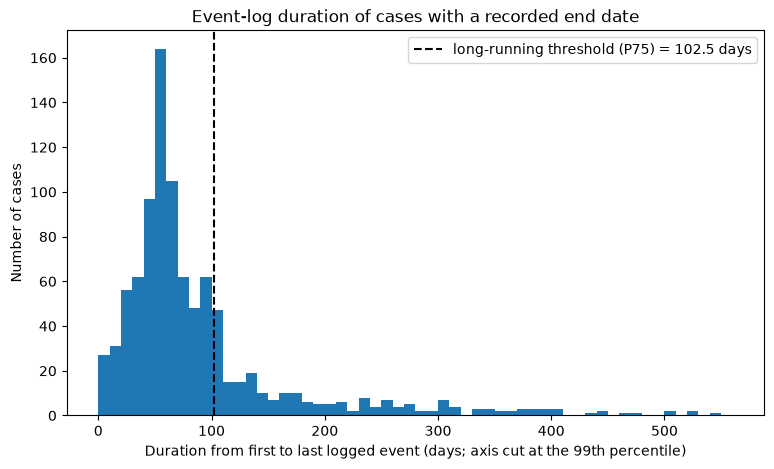

In [19]:
plt.figure(figsize=(9, 5))
plt.hist(cohort["event_log_days"], bins=np.arange(0, cohort["event_log_days"].quantile(0.99) + 10, 10))
plt.axvline(recommended_threshold, color="black", linestyle="--",
            label=f"long-running threshold (P75) = {recommended_threshold:.1f} days")
plt.title("Event-log duration of cases with a recorded end date")
plt.xlabel("Duration from first to last logged event (days; axis cut at the 99th percentile)")
plt.ylabel("Number of cases")
plt.legend()
plt.savefig(figures_dir / "long_running_threshold.png", dpi=150, bbox_inches="tight")
print("Saved:", (figures_dir / "long_running_threshold.png").relative_to(project_root))
plt.show()

### Summary of the decision

1. **Cohort:** all cases with a recorded `case:endDate`. `requestComplete` is **not** used as a cohort filter, because the cases it would remove look finished and are disproportionately long. The strict 774-case cohort is kept as a sensitivity analysis.
2. **Duration:** event-log duration (first → last logged event). The administrative duration is rejected as the primary definition because its large anomalies (late administrative closure, fixed waiting offsets) are concentrated in `endDate` and cluster in time.
3. **Rule:** a case is **long-running** if its event-log duration is **strictly greater** than the P75 of the cohort (threshold and counts in the table above).
4. **Prediction point:** 14 days after the first logged event, for cases still open at that moment. Trace-percentage prefixes are rejected.
5. **Evaluation:** chronological split by start date, with a follow-up restriction as a robustness check. No random split.

### Limitations to state in the presentation

- "Long-running" is **relative to this municipality's own cases** (upper quartile). It is not a legal deadline, statutory delay, lateness or a performance judgement.
- The labelled cohort contains only cases with a recorded closure. The 243 cases without one are excluded, and some of them are already long, so the cohort under-represents the longest cases (**right-censoring / selection**). Late start years are most affected (2014: only 62% of cases labelled).
- Timestamps are effectively **dates only**; durations are at day resolution and same-day event order is arbitrary.
- Event-log duration includes logged post-decision steps (publication, objections) and depends on every event being logged. A stray late event lengthens a case.
- The meaning of `requestComplete`, `caseStatus` and `endDate` is undocumented; conclusions about them are drawn from data patterns only.
- **Single municipality**, 2010–2015 (partial first and last years), ~1,000 labelled cases: results may not transfer to other municipalities or to SPAR data.
- The threshold is computed on the full cohort; the modelling step must confirm it on the training period.